# 4. Evaluation Metrics for Classification

### Decision Threshold in Machine Learning

The decision threshold in machine learning is a crucial factor in classifying data into binary classes. 

It is the value that determines how likely an instance is to be classified as a positive or negative class based on the model's output probabilities. 

For example, in binary classification, a model may output a probability score between 0 and 1, and if the score exceeds the threshold, the instance is classified as positive; otherwise, it is classified as negative. 

The default threshold is often set to 0.5, but this value may not be optimal for all scenarios, especially in cases with imbalanced classes or where the cost of false negatives outweighs the cost of false positives.

### Linspace in Python

The linspace function in Python's NumPy library generates evenly spaced numbers over a specified interval. 

It is commonly used for creating arrays with a specified number of elements between two endpoints.

## 4.1 Evaluation Metrics: Session Overview

**Metric** is a function that compares the predictions with the actual values and outputs a single number that tells how good the predictions are.

Inputs are predictions and true values. Outputs are a single number. 

Diffferent metrics look at different aspects of the predections. Picking the right metrick for the problemm is the topic of this entire module.

### Environment

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

# SciKit Learn

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# Old habits die hard
from datetime import datetime

### Data Read and Preparation

In [3]:
# Take the time to tell the time. Output is UTC
print(datetime.now())

2026-10-19 13:39:16.615589


In [4]:
# Reload ever time to avoid ValueError in `model.fit()` step
df = pd.read_csv('../03-classification/data-week-3.csv')

# Take spaces out of column headers
df.columns = df.columns.str.lower().str.replace(' ', '_')

# the below is 'object' is the instructor's repo; changed to 'str' here
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

# Everything everywhwere all at once
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

# Unparseable strings will be replaced with NaN
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

# Make values in churn column 0 or 1 instead of no or yes
"""
Claude: On the first run, `churn` holds the strings `'yes'` and `'no'`, 
and the line produces the correct 0s and 1s. If the cell runs again without 
`df` being reloaded from the CSV, `churn` already holds integers. No integer 
equals the string 'yes', so every comparison is False and the whole column 
becomes 0. Nothing raises an error at that point; the target is silently wiped.
"""
df.churn = (df.churn == 'yes').astype(int)

print(datetime.now())

2026-10-19 13:39:16.792206


In [5]:
df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic_check,29.85,29.85,0
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.50,0
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed_check,53.85,108.15,1
3,7795-cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,0
4,9237-hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month-to-month,yes,electronic_check,70.70,151.65,1


In [7]:
# Tracking down ValueError

df.churn.value_counts()

churn
0    5174
1    1869
Name: count, dtype: int64

### Split the data into training, validation and test groups

Set up the **validation framework**.

Then delete the target 'churn' column

### Gemini response to ValueError query:

1. Inspect Your Target Variable (`y_train`)
Check the unique values or value counts of your training target to see what it contains:

Python
print(y_train.value_counts())

If all rows evaluate to a single value (e.g., only `0` or only `1`), your model has nothing to contrast or learn from.

2. Verify Your Train/Validation/Test Splitting Code
This commonly happens due to one of a few setup issues earlier in the notebook:

Incorrect Target Column: Ensure you are selecting the correct target column from your DataFrame (e.g., matching the exact dataset column used in the course lecture, such as `.card` [*sic*, '.churn'?] or whatever binary target is specified for Week 4).

Target Leakage / Accidental Filtering: Check if you accidentally filtered or subsetted your DataFrame such that all rows in `df_train` belong to only one target category.

Random State / Shuffling: If you split your data using `train_test_split`, make sure you included a `random_state` parameter to ensure reproducible splits, and verify that shuffling wasn't turned off (which can sometimes pack all instances of a rare class into one split).

3. Re-run Preceding Cells
Go back to the section where data splits (`df_train`, `df_val`, `df_test`) and target definitions (`y_train`, `y_val`, `y_test`) are created, re-execute those cells to ensure the target variable is properly loaded and split, and then run your model training cell again.

### Claude's Retort:

Gemini’s suggestions about random_state and shuffling do not apply here. Your split code is correct; the target column was already all zeros before the split ran.

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

print(f"df_train: {len(df_train)}, df_val: {len(df_val)}, df_test: {len(df_test)}")

df_train: 4225, df_val: 1409, df_test: 1409


In [9]:
# Tracking down ValueError

df_train.churn.value_counts()

churn
0    3090
1    1135
Name: count, dtype: int64

In [10]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [11]:
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

In [12]:
# Tracking down ValueError

y_train.mean()

np.float64(0.2686390532544379)

In [13]:
type(y_train)

numpy.ndarray

In [14]:
del df_train['churn']
del df_val['churn']
del df_test['churn']

In [15]:
df_val.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges
0,5846-neqvz,male,0,yes,yes,71,yes,no,dsl,yes,no,yes,yes,no,yes,two_year,yes,credit_card_(automatic),70.85,4973.40
1,3645-deygf,male,0,no,yes,1,yes,no,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,month-to-month,no,mailed_check,20.75,20.75
2,3590-tcxtb,male,0,no,no,1,yes,no,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,month-to-month,no,mailed_check,20.35,20.35
3,8433-wxgna,male,0,no,no,2,yes,no,fiber_optic,yes,no,no,no,no,no,month-to-month,yes,electronic_check,75.70,189.20
4,2654-vbvpb,female,0,no,no,1,yes,no,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,month-to-month,no,bank_transfer_(automatic),19.90,19.90


### Define Numerical and Categorical Values

In [18]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

print(datetime.now())

2026-10-19 13:40:44.431355


### Training Logistic Regression

Heavy lifting happens here

**Feature importance* and **one-hot encoding** that featured in the last lesson are skipped at this point.

`Dictvectorizer()` is a SciKitLearn transformer. It has the `fit` step and the `transform` step.

In [19]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

print(datetime.now())

2026-10-19 13:40:53.374017


In [20]:
# Verifying fix to ValueError

np.unique(y_train, return_counts=True)

(array([0, 1]), array([3090, 1135]))

In [21]:
# Do we get more conformant numbers (Alexey) if we don't us this solver and max_iters?
# model = LogisticRegression(solver='lbfgs', max_iter=1000)
model = LogisticRegression()
model.fit(X_train, y_train)
# The answer is YES!

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

### Claude: What the warning means

The model has been fitted: the “LogisticRegression / Parameters / Fitted attributes” box is scikit-learn’s display of a trained model, not a prompt asking you to choose something. 

The warning says only that the optimiser stopped at its iteration limit before meeting its strict stopping criterion. 

The model is usable, and its predictions are almost certainly very close to those of a fully converged model.

In [22]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

### 4.2 Accuracy and Dummy Model

- Evaluate the model on different thresholds
- Check the accuracy of dummy baselines

In [23]:
len(y_val)

1409

In [24]:
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

In [25]:
1132 / 1409

0.8034066713981547

For Alexy `(y_val == churn_decision).mean()` and `1132 / 1409` yielded the same `0.8034066713981547`.

In [26]:
from sklearn.metrics import accuracy_score

In [27]:
accuracy_score(y_val, y_pred >= 0.5)

0.8034066713981547

In [28]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.274
0.05 0.509
0.10 0.591
0.15 0.667
0.20 0.710
0.25 0.737
0.30 0.760
0.35 0.772
0.40 0.785
0.45 0.793
0.50 0.803
0.55 0.801
0.60 0.795
0.65 0.786
0.70 0.765
0.75 0.744
0.80 0.735
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


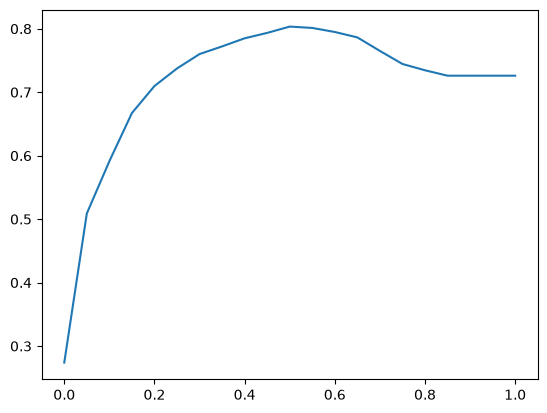

In [29]:
plt.plot(thresholds, scores)

In [30]:
from collections import Counter

In [31]:
Counter(y_pred >= 1.0)

Counter({np.False_: 1409})

In [32]:
1 - y_val.mean()

np.float64(0.7260468417317246)

## 4.3 Confusion Table

- Different types of errors and correct decisions
- Arranging them in a table

In [33]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

In [34]:
t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [35]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [36]:
(predict_positive & actual_positive)

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [37]:
(predict_positive & actual_positive).sum()

np.int64(210)

In [38]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[922, 101],
       [176, 210]])

### Element-wise Division by a Scalar / Total Sum

Dividing `confusion_matrix` by this single scalar value (`1409`) divides every individual cell (True Negatives, False Positives, False Negatives, and True Positives) by the total number of samples.

This turns the raw counts into proportions / percentages of the total dataset (which all sum up to 1 before rounding).

In [39]:
# Element-wise Division by a Scalar / Total Sum
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

## 4.4 Precision and Recall

In [40]:
p = tp / (tp + fp)
p

np.float64(0.6752411575562701)

Why did the above cell not return a result? Division by zero???

In [41]:
r = fp / (fp + tn)
r

np.float64(0.09872922776148582)

## 4.5 ROC Curves

Receiver Operating Characteristic Curbe

A graphical plot that illustrates the performance of a binary classifier model at verying threshold values.

It can be generalised to multiple classes.

It is a plot of the True Positive Rate versus the False Positive Rate across all classification threasholds.

The curve visualises the trade-off between detecting positives and avoiding false alarms.

It is used to evaluate the performance of binary classifiers.

### TPR and FRP

In [42]:
tpr = tp / (tp + fn)
tpr

np.float64(0.5440414507772021)

In [43]:
fpr = fp / (fp + tn)
fpr

np.float64(0.09872922776148582)

In [44]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

In [45]:
scores[:5]

[(np.float64(0.0), np.int64(386), np.int64(1023), np.int64(0), np.int64(0)),
 (np.float64(0.01), np.int64(385), np.int64(911), np.int64(1), np.int64(112)),
 (np.float64(0.02), np.int64(384), np.int64(829), np.int64(2), np.int64(194)),
 (np.float64(0.03), np.int64(383), np.int64(766), np.int64(3), np.int64(257)),
 (np.float64(0.04), np.int64(381), np.int64(715), np.int64(5), np.int64(308))]

In [46]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

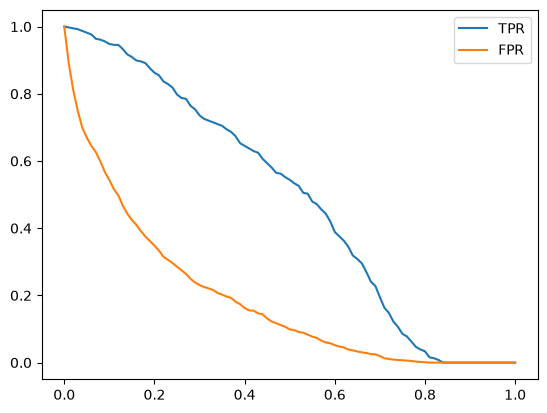

In [47]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

### Random Model

In [48]:
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))

In [49]:
((y_rand >= 0.5) == y_val).mean()

np.float64(0.5017743080198722)

In [50]:
def tpr_fpr_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
    
    return df_scores

In [51]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)

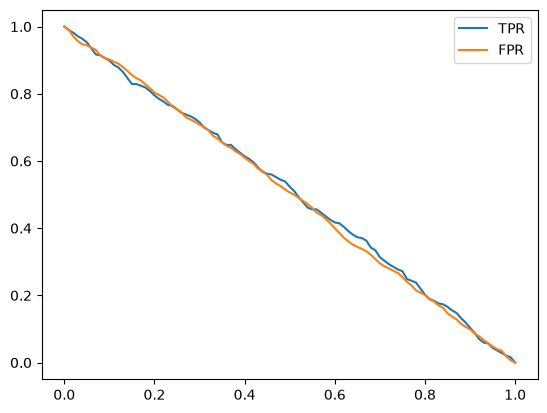

In [52]:
plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR')
plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR')
plt.legend()

### Ideal Model

In [53]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()
num_neg, num_pos

(np.int64(1023), np.int64(386))

In [71]:
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal

array([0, 0, 0, ..., 1, 1, 1], shape=(1409,))

In [54]:
y_ideal_pred = np.linspace(0, 1, len(y_val))

In [55]:
y_ideal_pred[:10]

array([0.        , 0.00071023, 0.00142045, 0.00213068, 0.00284091,
       0.00355114, 0.00426136, 0.00497159, 0.00568182, 0.00639205])

In [56]:
y_val[:10]

array([0, 0, 0, 1, 0, 0, 0, 0, 1, 1])

In [57]:
1 - y_val.mean()

np.float64(0.7260468417317246)

In [58]:
accuracy_score(y_ideal, y_ideal_pred >= 0.726)

1.0

In [59]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)
df_ideal[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,386,882,0,141,1.000000,0.862170
20,0.2,386,741,0,282,1.000000,0.724340
30,0.3,386,600,0,423,1.000000,0.586510
40,0.4,386,459,0,564,1.000000,0.448680
50,0.5,386,319,0,704,1.000000,0.311828
60,0.6,386,178,0,845,1.000000,0.173998
70,0.7,386,37,0,986,1.000000,0.036168
80,0.8,282,0,104,1023,0.730570,0.000000
90,0.9,141,0,245,1023,0.365285,0.000000


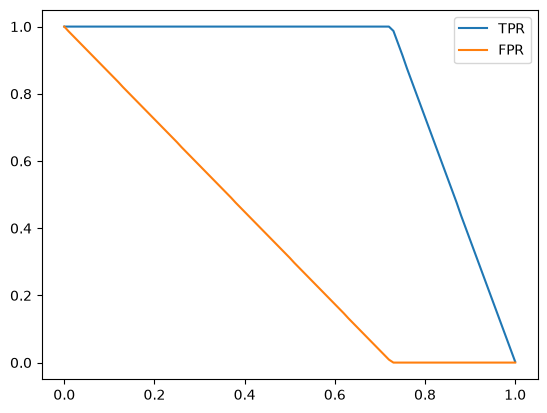

In [60]:
plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR')
plt.legend()

### Putting Everything Together

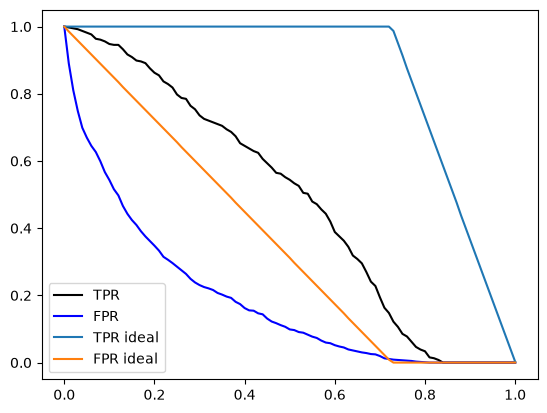

In [61]:

plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR', color='blue')

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR ideal')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR ideal')

# plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR random', color='grey')
# plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR random', color='grey')

plt.legend()

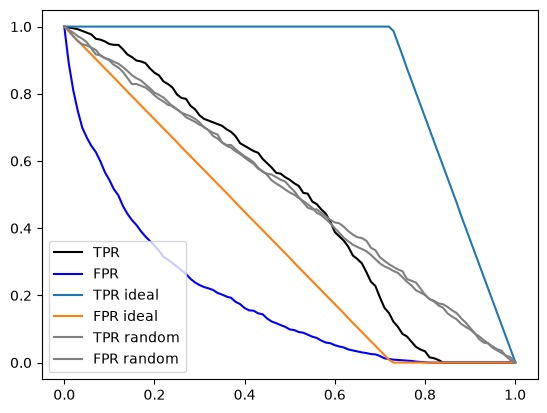

In [65]:

plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR', color='blue')

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR ideal')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR ideal')

plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR random', color='grey')
plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR random', color='grey')

plt.legend()

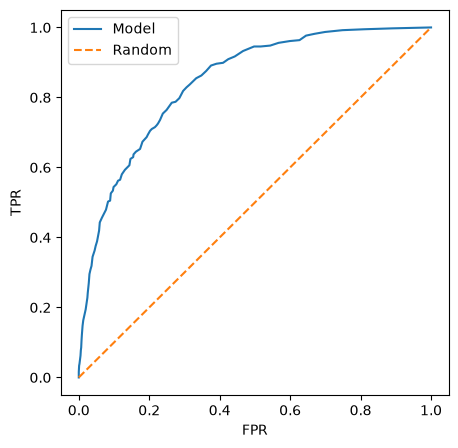

In [62]:
plt.figure(figsize=(5, 5))
plt.plot(df_scores.fpr, df_scores.tpr, label='Model')
plt.plot([0, 1], [0,1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [63]:
from sklearn.metrics import roc_curve

In [64]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

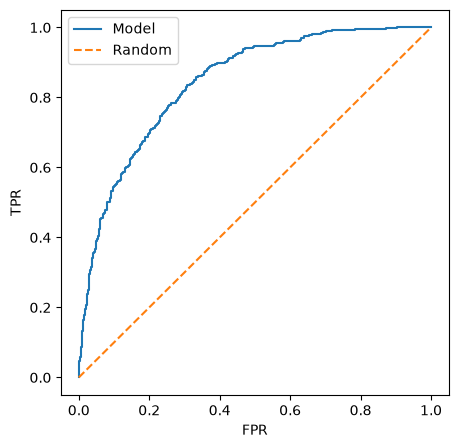

In [65]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

## 4.6 ROC AUC

- Area under the ROC curve is a useful metric
- Intrepretation of AUC

In [77]:
from sklearn.metrics import auc

print(datetime.now())

2026-10-19 13:56:35.121900


In [78]:
auc(fpr, tpr)

0.8438454408703447

In [79]:
auc(df_scores.fpr, df_scores.tpr)

0.8437909936739956

In [80]:
auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

In [81]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)
auc(fpr, tpr)

0.8438454408703447

In [82]:
from sklearn.metrics import roc_auc_score

In [83]:
roc_auc_score(y_val, y_pred)

0.8438454408703447

In [84]:
neg = y_pred[y_val == 0]
pos = y_pred[y_val == 1]

In [85]:
import random

In [87]:
n = 100_000
success = 0

for i in range(n):
    pos_ind = random.randint(0, len(pos) - 1)
    neg_ind = random.randint(0, len(neg) - 1)

    if pos[pos_ind] > neg[neg_ind]:
        success = success + 1

success / n

0.84358

In [88]:
n = 50_000

np.random.seed(1)
pos_ind = np.random.randint(0, len(pos), size=n)
neg_ind = np.random.randint(0, len(neg), size=n)

(pos[pos_ind] > neg[neg_ind]).mean()

np.float64(0.84646)

## 4.7 Cross-Validation

- Evaluating the same model on different subsets of data
- Getting the average prediction and the spread within predictions

In [90]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

print(datetime.now())

2026-10-19 14:02:29.697201


In [91]:
dv, model = train(df_train, y_train, C=0.001)

In [92]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

print(datetime.now())

2026-10-19 14:04:18.814965


In [93]:
y_pred = predict(df_val, dv, model)

In [94]:
from sklearn.model_selection import KFold

In [95]:
!pip install tqdm

In [96]:
from tqdm.auto import tqdm

In [97]:
n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.churn.values
        y_val = df_val.churn.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.825 +- 0.009


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=0.01 0.840 +- 0.008


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=0.1 0.842 +- 0.007


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=0.5 0.842 +- 0.007


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=1 0.842 +- 0.007


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=5 0.842 +- 0.007


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preproc

C=10 0.842 +- 0.007


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [98]:
scores

[0.8445612327401464,
 0.8450846742153357,
 0.8333172787477423,
 0.8348048698599475,
 0.8519265162687082]

In [99]:
dv, model = train(df_full_train, df_full_train.churn.values, C=1.0)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

0.8583517501381259

## 4.8 Summary

- A **metric** is a single number that describes the performance of a model
- **Accuracy** is the fraction of correct answers. It is misleading when a single value dominates the target variable (class imbalance)
- **Precision** and **recall** are less misleading when we have a class imbalance
- **K-Fold CV** is a more reliable estimate for performance; it is mean + std